In [ ]:
import numpy as np
import pandas as pd
import lseg.data as ld
import matplotlib.pyplot as plt

In [ ]:
ld.open_session()

df = ld.get_history("EURCAD=", 
                    fields=["ASK", "BID"],
                    interval="30min",
                    start="2025-01-01",
                    end="2025-12-31",
                    )

print(df.head())
print(df.dtypes)

EURCAD=                 ASK     BID
Timestamp                          
2025-05-12 17:30:00  1.5525  1.5514
2025-05-12 18:00:00   1.551  1.5505
2025-05-12 18:30:00  1.5521  1.5515
2025-05-12 19:00:00   1.552  1.5515
2025-05-12 19:30:00  1.5516  1.5514
EURCAD=
ASK    Float64
BID    Float64
dtype: object


## Simple Moving Average

SMA - average equally based on the count

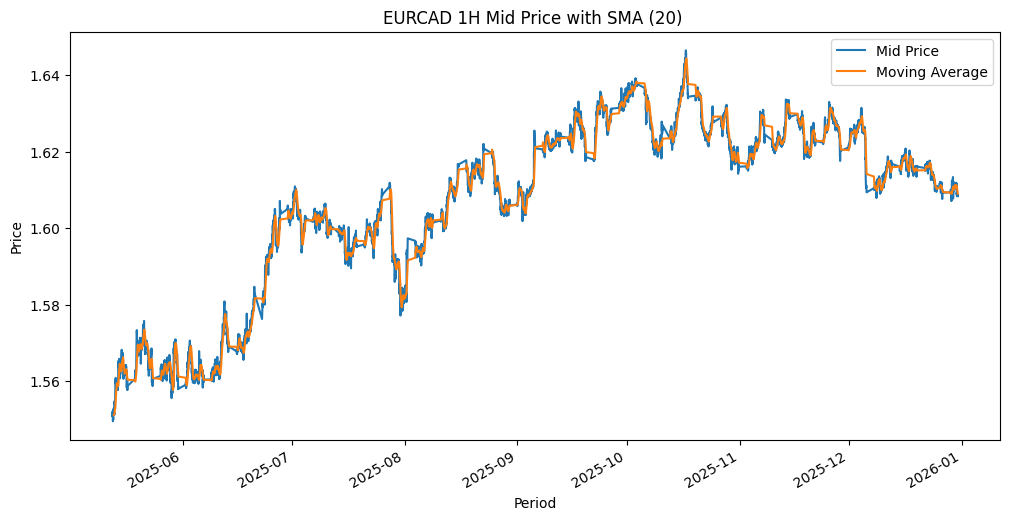

In [ ]:
df["MID"] = (df["ASK"] + df["BID"]) / 2

df["MA"] = df["MID"].rolling(window=20).mean()

plt.figure(figsize=(12,6))
df["MID"].plot(label="Mid Price")
df["MA"].plot(label="Moving Average")
plt.title("EURCAD 1H Mid Price with SMA (20) ")

plt.legend()
plt.ylabel("Price")
plt.xlabel("Period")
plt.show()


## EWMA - Exponential Weighted Moving Average

EWMA - weightage of average based on how recent it is, decreasing weights to older data

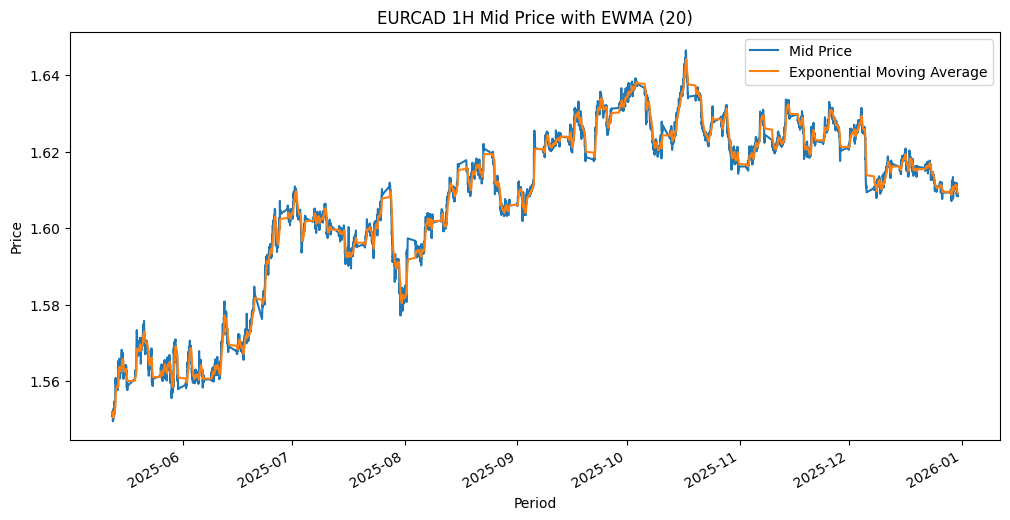

In [ ]:
df["EWMA"] = df["MID"].ewm(span=20).mean()

plt.figure(figsize=(12,6))
df["MID"].plot(label="Mid Price")
df["EWMA"].plot(label="Exponential Moving Average")

plt.title("EURCAD 1H Mid Price with EWMA (20)")
plt.legend()
plt.ylabel("Price")
plt.xlabel("Period")
plt.show()

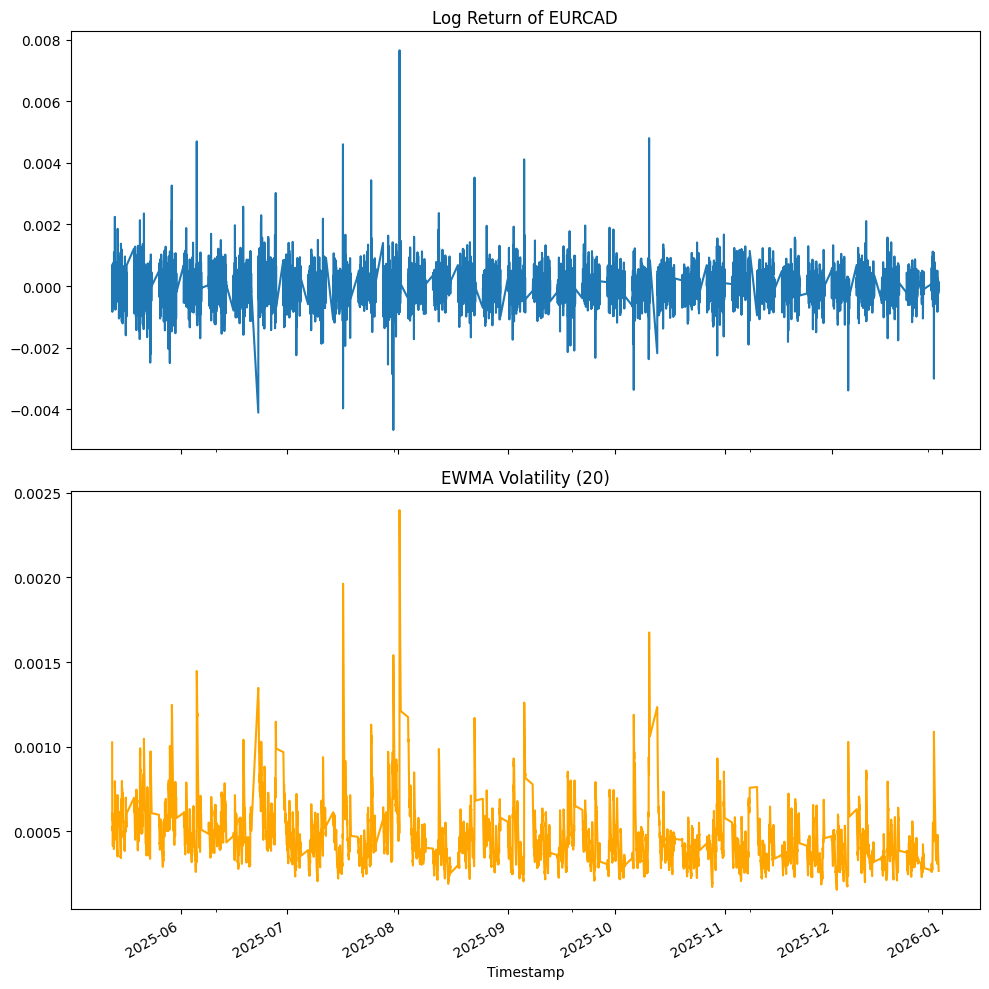

In [ ]:
df["RETURNS"] = np.log(df["MID"] / df["MID"].shift(1))

df["EWMA_VOL"] = df["RETURNS"].ewm(span=20).std()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

df["RETURNS"].plot(ax=ax1, label="Returns")
ax1.set_title("Log Return of EURCAD")

df["EWMA_VOL"].plot(ax=ax2, label="EWMA Volatility", color="orange")
ax2.set_title("EWMA Volatility (20)")

plt.tight_layout()
plt.show()
